# Evaluating a classifier

Last week you fitted models and asked how well they did. This notebook is about that
second half of the question: deciding what "well" means, and spotting when a number
that looks good is hiding something.

Everything uses datasets that come with scikit-learn, so there is nothing to download.
This notebook has two parts. Section 1 is to learn the scikit-learn pattern itself: how
you load data, hold some back, fit a model and score it. Section 2 focuses on the metrics.
You will meet the different classifier families properly next week.

Run each cell as you go. The exercises are short, and the answers are in the fold
underneath, but have a go before you open them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine, load_digits, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

## 1. How scikit-learn is put together

**scikit-learn** is the standard Python library for machine learning. Its best feature is
that it is boring: every model, however different it is on the inside, is driven through
the same few method calls. Learn the pattern once and you can swap one model for another
without rewriting anything around it.

A model object is called an **estimator**. You will use three of its methods:

| call | what it does |
| --- | --- |
| `model.fit(X, y)` | learn from the training data |
| `model.predict(X)` | give a label for each row of new data |
| `model.score(X, y)` | the fraction of labels it gets right |

Two conventions about the data are used. `X` is two-dimensional: one
row per example, one column per feature. `y` is one-dimensional: one label per row of `X`.
A good share of confusing scikit-learn errors are really just those shapes being wrong.

In [2]:
wine = load_wine()

print("X shape:", wine.data.shape)        # (rows, features)
print("y shape:", wine.target.shape)      # one label per row
print("features:", wine.feature_names[:3], "...")
print("classes: ", list(wine.target_names), np.bincount(wine.target))

X shape: (178, 13)
y shape: (178,)
features: ['alcohol', 'malic_acid', 'ash'] ...
classes:  [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')] [59 71 48]


178 wines, 13 chemical measurements each, three varieties spread fairly evenly.

Next, hold some data back (the test set). `train_test_split` shuffles and cuts the data in one
line command. `random_state` fixes the shuffle so your numbers match the ones here, and
`stratify` keeps the three varieties in the same proportions on both sides of the split.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, test_size=0.3, random_state=0, stratify=wine.target)

print("train:", X_train.shape, " test:", X_test.shape)

train: (124, 13)  test: (54, 13)


124 wines to learn from, 54 held back. Now the three calls.

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

print("predicted:", model.predict(X_test)[:20])
print("actual:   ", y_test[:20])
print("test score:", round(model.score(X_test, y_test), 3))

predicted: [0 1 0 0 1 2 1 2 0 2 0 1 2 0 2 2 0 0 2 0]
actual:    [0 1 0 0 1 2 1 2 0 2 0 1 2 0 2 2 0 0 2 1]
test score: 0.963


0.963, so it labels about 96% of wines it has never seen correctly. That is the whole
pattern: pick a model, `fit` on the training half, then `predict` or `score` on the
held-out half. Everything else in this notebook is about what to do when that single
score is not enough.

> ### Your turn 1
>
> Swap the model for a `KNeighborsClassifier()` and score it the same way. You should
> only need to change one line. Does the interface care which model you chose? Does the
> score?

In [9]:
# TODO: fit a KNeighborsClassifier on the same split and print its test score

from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()
model.fit(X_train, y_train)

print("predicted:", model.predict(X_test)[:20])
print("actual:   ", y_test[:20])
print("test score:", round(model.score(X_test, y_test), 3))

predicted: [0 1 0 0 2 0 2 2 0 2 0 1 1 0 2 1 0 0 1 0]
actual:    [0 1 0 0 1 2 1 2 0 2 0 1 2 0 2 2 0 0 2 1]
test score: 0.722


<details>
<summary>Answer</summary>

```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()
knn.fit(X_train, y_train)
print("test score:", round(knn.score(X_test, y_test), 3))
```

0.722, against 0.963 for logistic regression. The interface did not change at all - the
same three calls in the same order - but the answer changed a great deal. Why
k-nearest-neighbours does badly on this particular dataset is next week's subject.

</details>

> ### Your turn 2
>
> Fit a `DecisionTreeClassifier(random_state=0)` on the same training data and score it
> twice: once on the training data, once on the test data. What do you make of the two
> numbers?

In [ ]:
# TODO: fit a decision tree, then score it on the training set and the test set

<details>
<summary>Answer</summary>

```python
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("train score:", round(tree.score(X_train, y_train), 3))
print("test score: ", round(tree.score(X_test, y_test), 3))
```

1.000 on the training data and 0.944 on the test data. The tree has memorised every
training wine perfectly, which tells you nothing at all about a wine it has not seen.
That gap is the entire reason for splitting: a training score is not evidence. From here
on, every number in this notebook comes from a test set.

</details>

## 2. Accuracy on its own can be useless

The wine varieties were spread fairly evenly - 59, 71 and 48 - so that test score was a
fair summary of the model. Now, let's look at a problem where it is not.

We will ask one question of the handwritten digits dataset: **is this digit an 8?** That
turns it into a two-class problem where one class is rare, which is where evaluation gets
interesting.

In [10]:
digits = load_digits()
X = digits.data
y = (digits.target == 8).astype(int)      # 1 if the digit is an 8, 0 otherwise

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0, stratify=y)

print("images:", len(y), " eights:", y.sum(), f"({y.mean():.1%})")

images: 1797  eights: 174 (9.7%)


About one image in ten is an 8. Now here is a model that has given up completely:
it always predicts the most common class.

In [11]:
from sklearn.metrics import accuracy_score

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("accuracy:", round(accuracy_score(y_test, dummy.predict(X_test)), 3))

accuracy: 0.904


Just over 90%, from a model that never says "8" at all. **Accuracy** — the fraction of
predictions that are correct — pays it for ignoring the thing you actually asked about.
Any time one class is rare, accuracy will flatter a model like this.

> ### Your turn 3
>
> Show that the dummy really never predicts an 8: print the unique values it
> predicts on the test set, and its recall for class 1.

In [15]:
# TODO: unique predicted values, and recall_score for class 1

from sklearn.metrics import recall_score

<details>
<summary>Answer</summary>

```python
from sklearn.metrics import recall_score

pred = dummy.predict(X_test)
print(np.unique(pred))              # [0] - it only ever says "not an 8"
print(recall_score(y_test, pred))   # 0.0 - it catches none of them
```

</details>

## 3. The confusion matrix

Now let's try a better model. Same three calls as section 1, new dataset.

In [16]:
clf = LogisticRegression(max_iter=5000).fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("accuracy:", round(accuracy_score(y_test, y_pred), 3))

accuracy: 0.963


96%, so clearly better than the dummy's 90%. But accuracy still only tells you how often
the model was right, never what it got wrong. The **confusion matrix** splits the
predictions into the four things that can happen.

[[482   6]
 [ 14  38]]


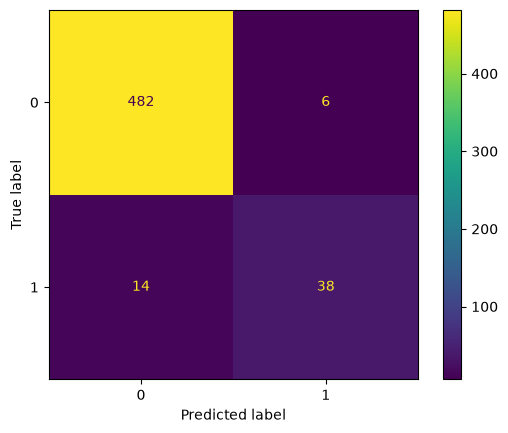

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(confusion_matrix(y_test, y_pred))

ConfusionMatrixDisplay.from_estimator(clf, X_test, y_test)
plt.show()

Two things to be careful about.

**Rows are the truth, columns are the prediction.** This is the transpose of the square
we drew in the lecture, where the truth ran across the columns so that column width
could show the base rate. Neither is wrong, but they are mirror images of each other, so
read the axis labels every time rather than relying on habit.

**`.ravel()` does not unpack in the order you pass.** It gives you
`tn, fp, fn, tp`, not `tp, fp, fn, tn`.

In [18]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"tn={tn}  fp={fp}  fn={fn}  tp={tp}")

tn=482  fp=6  fn=14  tp=38


> ### Your turn 4
>
> The model is 96% accurate. Using the numbers above: how many of the eights in the
> test set did it miss completely, and what fraction of all the eights is that?

In [20]:
# TODO: how many eights were missed, and what fraction of the eights that is

miss8 = fn/(fn+tp)

print(miss8, "%")

0.2692307692307692 %


<details>
<summary>Answer</summary>

```python
print(fn, "missed out of", fn + tp)
print(f"{fn / (fn + tp):.1%} of the eights")
```

15 of the 52 eights, so it misses 28.8% of them. A model that is "96% accurate" is
missing more than a quarter of the thing you asked it to find. Accuracy never showed you
this, because the 488 non-eights swamp it.

</details>

## 4. Precision, recall and F1

Two numbers describe the two ways of being wrong.

**Precision** — of the cases the model flagged, what fraction were really eights:
`tp / (tp + fp)`. It drops when the model cries wolf.

**Recall** — of the cases that really were eights, what fraction the model caught:
`tp / (tp + fn)`. It drops when the model misses things.

**F1** is their harmonic mean, for when you want one number rather than two.
`classification_report` prints all of them for every class at once.

In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=["not an 8", "an 8"]))

              precision    recall  f1-score   support

    not an 8       0.97      0.99      0.98       488
        an 8       0.86      0.73      0.79        52

    accuracy                           0.96       540
   macro avg       0.92      0.86      0.89       540
weighted avg       0.96      0.96      0.96       540



Read the "an 8" row rather than the accuracy line. Precision 0.86, recall 0.71: when it
says "8" it is usually right, but it only finds about seven in ten. Those are very
different failures, and the single accuracy figure showed neither.

> ### Your turn 5
>
> Compute precision and recall yourself from `tn, fp, fn, tp`, and check they match
> the report.

In [26]:
# TODO: precision and recall from the four counts

print("precision", round(tp/(tp+fp), 3))
print("recall", round(tp/(tp+fn), 3))

precision 0.864
recall 0.731


<details>
<summary>Answer</summary>

```python
print("precision:", round(tp / (tp + fp), 3))   # 0.86
print("recall:   ", round(tp / (tp + fn), 3))   # 0.712
```

</details>

## 5. The threshold is a choice, not a property of the model

The model does not really output a class. It outputs a probability, and `predict` uses by default 0.5 to predict the label. That threshold is a decision you are allowed to make differently.

In [ ]:
proba = clf.predict_proba(X_test)[:, 1]     # probability of class 1, "an 8"
print(proba[:5].round(3))

In [ ]:
from sklearn.metrics import precision_score, recall_score

for t in [0.1, 0.5, 0.9]:
    flagged = (proba >= t).astype(int)
    print(f"threshold {t}:  flagged {flagged.sum():3d}"
          f"   precision {precision_score(y_test, flagged):.3f}"
          f"   recall {recall_score(y_test, flagged):.3f}")

Drop the threshold and you catch more eights while being wrong more often. Raise it and
you are right almost every time you speak, but you stay quiet about half the eights.
Nothing about the fitted model changed between those rows. Only the cut moved.

There is a browser version of this you can drag around:
<https://chri4354.github.io/threshold-explorer/>

> ### Your turn 6
>
> Sweep the threshold from 0.1 to 0.9 in steps of 0.1 and find the value where
> precision and recall are closest to each other.

In [ ]:
# TODO: sweep thresholds, print precision and recall, find where they nearly meet

<details>
<summary>Answer</summary>

```python
for t in np.arange(0.1, 1.0, 0.1):
    flagged = (proba >= t).astype(int)
    p = precision_score(y_test, flagged)
    r = recall_score(y_test, flagged)
    print(f"{t:.1f}  precision {p:.3f}  recall {r:.3f}  gap {abs(p - r):.3f}")
```

They cross between 0.2 and 0.3, and 0.3 is the closest of the steps tested
(precision 0.824, recall 0.808). Note that this balance point has nothing to do with
0.5 — there is no reason the default cut should be the balanced one.

</details>

## 6. ROC and AUC: every threshold at once

Instead of picking one threshold, plot all of them. The **ROC curve** traces the true
positive rate against the false positive rate as the cut sweeps from high to low, and
**AUC** is the area underneath it: 0.5 is a coin toss, 1.0 is perfect.

In [ ]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.show()

print("AUC:", round(roc_auc_score(y_test, proba), 3))

> ### Your turn 7
>
> Fit a `DecisionTreeClassifier(max_depth=3, random_state=0)` on the same data and
> draw both ROC curves on one axes. Pass `ax=` to the second call to reuse the first
> plot. Which model looks better, and by how much?

In [ ]:
# TODO: fit a shallow tree, plot both ROC curves together, print both AUCs

<details>
<summary>Answer</summary>

```python
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_train, y_train)

ax = plt.gca()
RocCurveDisplay.from_estimator(clf, X_test, y_test, ax=ax, name="logistic")
RocCurveDisplay.from_estimator(tree, X_test, y_test, ax=ax, name="tree, depth 3")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.show()
```

AUC 0.978 for the logistic model against 0.889 for the tree. The tree is worse, but
0.889 still sounds respectable. Hold onto that number for the next section.

</details>

## 7. The precision-recall curve

AUC has a blind spot. The false positive rate divides by the number of negatives, and
there are 488 of those, so a handful of false alarms barely registers. Precision divides
by the number of cases you flagged, which is small, so the same handful matters a lot.

The **precision-recall curve** plots precision against recall across the thresholds, and
**average precision** is the area under it. Its floor is not 0.5 — it is the base rate.

In [ ]:
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

PrecisionRecallDisplay.from_estimator(clf, X_test, y_test)
plt.show()

print("average precision:", round(average_precision_score(y_test, proba), 3))
print("base rate:        ", round(y_test.mean(), 3))

> ### Your turn 8
>
> For the logistic model and the depth-3 tree, print AUC and average precision side
> by side. Which of the two comparisons makes the tree look worse, and why would that
> be?

In [ ]:
# TODO: AUC and average precision for both models

<details>
<summary>Answer</summary>

```python
for name, model in [("logistic", clf), ("tree, depth 3", tree)]:
    p = model.predict_proba(X_test)[:, 1]
    print(f"{name:14s} AUC {roc_auc_score(y_test, p):.3f}"
          f"   average precision {average_precision_score(y_test, p):.3f}")
```

| model | AUC | average precision |
|---|---|---|
| logistic | 0.978 | 0.888 |
| tree, depth 3 | 0.889 | 0.482 |

AUC makes the tree look mediocre; average precision makes it look poor. The gap between
the two models is around 0.09 on AUC and over 0.4 on average precision, so the second
comparison separates them more than four times as sharply. Against a base rate of 0.096,
the tree's 0.482 sits much closer to the floor than its AUC of 0.889 suggests.

This is the same point as the lecture's base-rate argument, arriving from the other
direction: when the positive class is rare, rates computed within the negative class
stay comfortable while precision does not.

</details>

## 8. A different dataset

The breast cancer dataset is a two-class problem where the two mistakes plainly cost
different amounts. Before computing anything, check what the labels mean.

In [ ]:
cancer = load_breast_cancer()
print(cancer.target_names)        # index 0 and index 1, in that order

So `0` is malignant and `1` is benign. scikit-learn's `precision_score`, `recall_score`
and `f1_score` all default to `pos_label=1`, which here means they report on **benign**
unless you tell them otherwise — the opposite of what anyone in a clinic cares about.

> ### Your turn 9
>
> Split the cancer data, fit a `LogisticRegression` wrapped in
> `make_pipeline(StandardScaler(), ...)`, and print the confusion matrix and the
> classification report with `target_names=cancer.target_names`.
>
> Then answer two things: how many malignant tumours were called benign, and does
> `recall_score(y_test, y_pred)` with no other arguments give you that number?

In [ ]:
# TODO: split, fit a scaled logistic regression, print the matrix and the report

<details>
<summary>Answer</summary>

```python
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    cancer.data, cancer.target, test_size=0.3, random_state=0, stratify=cancer.target)

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
model.fit(Xc_train, yc_train)
yc_pred = model.predict(Xc_test)

print(confusion_matrix(yc_test, yc_pred))
print(classification_report(yc_test, yc_pred, target_names=cancer.target_names))

print("default recall  :", round(recall_score(yc_test, yc_pred), 3))
print("malignant recall:", round(recall_score(yc_test, yc_pred, pos_label=0), 3))
```

The matrix is `[[61, 3], [4, 103]]`. Row 0 is malignant, so **3 malignant tumours were
called benign**.

No, the default does not give you that. `recall_score` with no `pos_label` returns
0.963, which is the recall for benign. The malignant recall is 0.953, via `pos_label=0`.
The two numbers are close here, so a wrong one would not look obviously wrong — which is
exactly what makes it worth checking rather than assuming.

</details>

## What to take away

- Every scikit-learn model is driven the same way: `fit` on the training data, then
  `predict` or `score` on data it has not seen. Changing model family is a one-line edit.
- A training score is never evidence. Always report score on testing set or (even better) 
  cross validated sets.
- Accuracy is the fraction correct, and on an imbalanced problem a model that does
  nothing can score well on it. Always check it against a `DummyClassifier`.
- The confusion matrix is the raw material. Precision and recall are two readings of it
  that fail in opposite directions. `classification_report` gives you both per class.
- scikit-learn puts the truth in the rows and the prediction in the columns, and
  `.ravel()` returns `tn, fp, fn, tp`. Read the labels.
- The threshold is your decision, not the model's. Moving it trades precision against
  recall without refitting anything.
- ROC and AUC sweep every threshold, but are not great when the positive class is rare.
  The precision-recall curve and average precision are the best plot in these cases, and
  average precision has the base rate as its floor.
- Check `pos_label` before you believe a precision, recall or F1 score.